# 03 · SVM con kernel gaussiano (RBF)
**Responsable:** Alejandro Flores

La lógica del modelo está en `src/models/svm_gaussiano.py` → función `construir_clasificador()`.
Este notebook solo entrena, evalúa, analiza y exporta usando el flujo común
(misma partición, mismo preprocesamiento y mismas métricas que los otros modelos).

El kernel gaussiano calcula $K(x, x') = \exp(-\gamma \, \lVert x - x' \rVert^2)$: la similitud entre dos URLs decae con
su distancia en el espacio de las 22 variables escaladas. Así la frontera de decisión puede tomar cualquier forma (no lineal), y
`gamma = "scale"` ajusta el radio de influencia de cada vector de soporte a la varianza de los datos.

In [1]:
# Configuración: permite importar el código común de src/ desde la carpeta notebooks/
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
plt.style.use("ggplot")
sns.set_palette("muted")

from src import config, data, evaluation
from src.training import entrenar_y_evaluar, exportar_final

CLAVE = "svm_rbf"
import time

## 1. Datos

In [2]:
df = data.cargar_dataset()
print(df.shape)

(115231, 26)


## 2. Entrenamiento (80%) y evaluación (20%)

In [3]:
inicio = time.time()
pipeline, metricas, (X_test, y_test) = entrenar_y_evaluar(CLAVE, df)
print(f"Tiempo de entrenamiento y evaluación: {time.time() - inicio:.0f} s")
pipeline

Tiempo de entrenamiento y evaluación: 350 s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesador', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['url_len','dom_len','tld_len',...,'digit_ratio','spec_ratio','entropy']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining c

In [4]:
print(metricas["reporte"])
print({k: round(metricas[k], 4) for k in ("accuracy", "precision", "recall", "f1", "auc")})

              precision    recall  f1-score   support

 Benigna (0)       0.98      0.99      0.98     19729
Phishing (1)       0.92      0.90      0.91      3318

    accuracy                           0.97     23047
   macro avg       0.95      0.94      0.95     23047
weighted avg       0.97      0.97      0.97     23047

{'accuracy': 0.974, 'precision': 0.9154, 'recall': 0.903, 'f1': 0.9091, 'auc': 0.9906}


## 3. Matriz de confusión

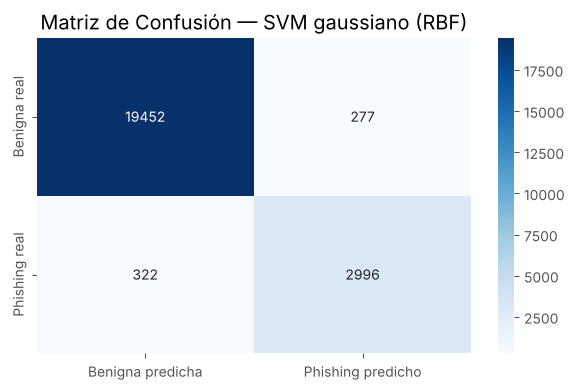

In [5]:
evaluation.graficar_matriz_confusion(metricas, f"Matriz de Confusión — {metricas['modelo']}")
plt.show()

**Interpretación** (conjunto de prueba: 23.047 URLs, 3.318 de phishing):

- **Verdaderos positivos (TP = 2.996):** phishing detectado. **Recall = 90,3 %**: de cada 100 ataques, detecta 90.
- **Falsos negativos (FN = 322):** phishing que se escapó. Son 2,5 veces menos que en el SVM lineal (803)
  y solo 58 más que la Regresión Logística (264), que a cambio genera 5 veces más falsas alarmas.
- **Falsos positivos (FP = 277):** URLs legítimas marcadas como phishing. **Precision = 91,5 %**: más de 9 de cada 10
  alertas son ataques reales.
- **Verdaderos negativos (TN = 19.452):** URLs legítimas reconocidas como tales.

El SVM gaussiano logra el **mejor equilibrio** entre ataques no detectados y falsas alarmas (F1 = 0,909).

## 4. Curva ROC

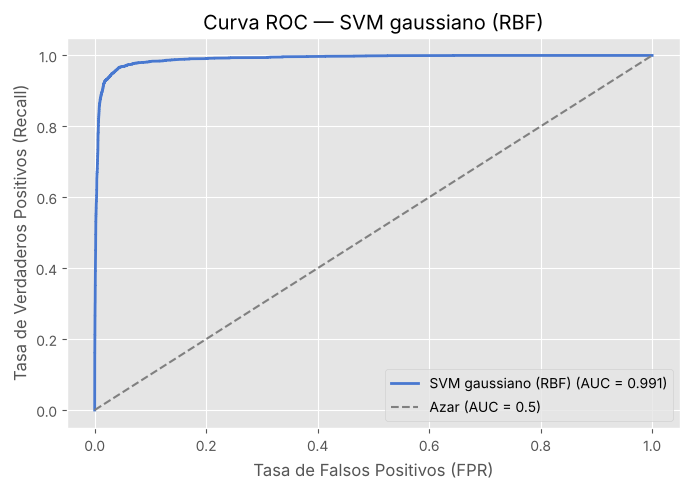

In [6]:
evaluation.graficar_roc({metricas["modelo"]: pipeline}, X_test, y_test, f"Curva ROC — {metricas['modelo']}")
plt.show()

## 5. Análisis del modelo: vectores de soporte y probabilidades

,Vectores de soporte,% del entrenamiento
Benigna (0),9556,10.4
Phishing (1),2017,2.2
Total,11573,12.6


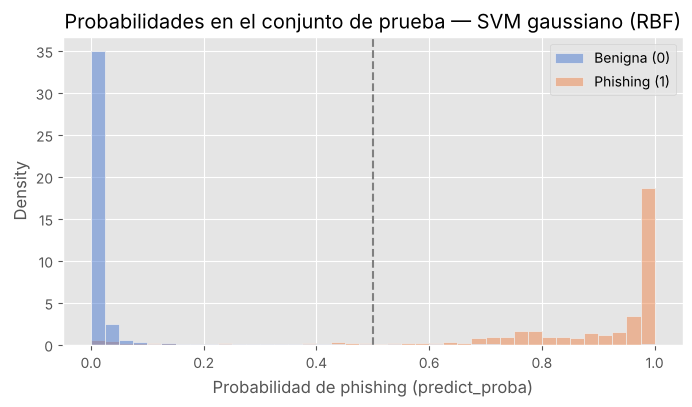

In [7]:
modelo = pipeline.named_steps["modelo"]
n_train = int(len(df) * (1 - config.TEST_SIZE))
vs = pd.DataFrame({"Vectores de soporte": modelo.n_support_},
                  index=["Benigna (0)", "Phishing (1)"])
vs.loc["Total"] = vs.sum()
vs["% del entrenamiento"] = (vs["Vectores de soporte"] / n_train * 100).round(1)
display(vs)

# Distribución de la probabilidad de phishing que asigna el modelo, por clase real
proba = pipeline.predict_proba(X_test)[:, 1]
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(x=proba, hue=y_test.map({0: "Benigna (0)", 1: "Phishing (1)"}).values, bins=40,
             stat="density", common_norm=False, ax=ax)
ax.axvline(config.UMBRAL_PHISHING, ls="--", color="gray")
ax.set_xlabel("Probabilidad de phishing (predict_proba)")
ax.set_title(f"Probabilidades en el conjunto de prueba — {metricas['modelo']}")
plt.show()

**Interpretación:**

- El modelo usa **11.573 vectores de soporte** (12,6 % del entrenamiento), 2.017 de ellos de phishing. Cada uno actúa como
  un "punto de referencia": una URL nueva se clasifica según su similitud gaussiana con ellos.
- El histograma muestra una separación muy clara: las benignas se concentran cerca de 0 y el phishing cerca de 1, con
  pocos casos en la zona intermedia del umbral (0,5).
- Frente al SVM lineal (mismo `C = 1`), el kernel gaussiano sube el Recall de 75,8 % a 90,3 % y el AUC de 0,976 a 0,991:
  una **frontera no lineal** separa mucho mejor las URLs de phishing que un hiperplano.
- Mejora posible: con el umbral de 0,5 sobre las probabilidades de Platt se pierde algo de Recall; bajar el umbral o
  ajustar `C` y `gamma` con validación cruzada podría detectar más phishing a costa de algunas falsas alarmas más.

## 6. Exportación (reentrenado con el 100% de los datos)

In [8]:
ruta = exportar_final(CLAVE, df)
print("Modelo exportado en:", ruta)

Modelo exportado en: models/modelo_svm_rbf.pkl


## 7. Conclusiones

- El SVM gaussiano (RBF, `C = 1`, `gamma = "scale"`) obtiene **F1 = 0,909**, **AUC = 0,991**, Recall = 90,3 %,
  Precision = 91,5 % y Accuracy = 97,4 %: el **mejor F1 y AUC de los tres modelos**.
- Combina pocos ataques no detectados (322) con pocas falsas alarmas (277), gracias a su frontera de decisión no lineal.
- Costo: ≈ 6 minutos para entrenar y evaluar con 92.184 URLs y un `.pkl` de ≈ 0,5 MB; la predicción de una URL en la
  app es instantánea.
- Es el **candidato a modelo ganador**, que se confirma en el notebook `05`.